# Task 1: Data Cleaning Project
**WeIntern Pvt Ltd | Data Science Internship | Week 2 Assignment**

**Author:** Vidit

---

## Objective
Transform a raw, messy real-world retail dataset into a clean, analysis-ready dataset. The cleaned output of this notebook is the input for Task 2 (Exploratory Data Analysis) and Task 3 (Sales Prediction Model), so every cleaning decision is documented and justified.

## Dataset
**Online Retail dataset** (UCI Machine Learning Repository): transactions of a UK-based online retailer, about 541,909 rows and 8 original columns.

| Column | Meaning |
|---|---|
| InvoiceNo | Invoice number. A leading "C" marks a cancelled invoice |
| StockCode | Product code |
| Description | Product name |
| Quantity | Units per transaction (negative values indicate returns) |
| InvoiceDate | Date and time of the transaction |
| UnitPrice | Price per unit in GBP |
| CustomerID | Customer identifier |
| Country | Customer country |

## Workflow of this notebook
1. Import libraries
2. Load the dataset
3. Initial exploration
4. Remove the extra index column
5. Baseline data quality snapshot (the "before" metrics)
6. Missing values, duplicates, data types, outliers, encoding, validation, export (next sections)

## Step 1: Import Libraries

**What:** Load the Python libraries used throughout the notebook.

**Why:** Python's core language has no tools for tables, numerical work, or charts. Each library has a specific role:
- `pandas`: table (DataFrame) handling, which is the backbone of all cleaning work
- `numpy`: fast numerical operations, used later for outlier calculations
- `matplotlib` and `seaborn`: visualizations such as the missing-data heatmap and box plots

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings for readable output
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_style("whitegrid")

## Step 2: Load the Raw Dataset

**What:** Read the raw CSV file into a pandas DataFrame named `df`.

**Why:** All later steps operate on this DataFrame. The raw file itself is never modified, so the original data stays intact and the cleaning process remains reproducible.

**Note:** pandas can read a CSV directly from inside a `.zip` file, so no manual extraction is required.

In [2]:
df = pd.read_csv("/content/online_retail.csv (1).zip")
print("Dataset loaded successfully.")

Dataset loaded successfully.


### Load result
The raw file was read successfully into the DataFrame `df`. The dataset is read directly from the compressed `.zip` file, and the original file is left untouched.

## Step 3: Initial Exploration

**What:** Inspect the structure and content of the data using `.shape`, `.info()`, `.head()` and `.describe()`.

**Why:** Cleaning without understanding the data leads to wrong decisions. This step answers four questions:
- How large is the dataset? (`.shape`)
- What data type does each column have, and where are nulls? (`.info()`)
- What does the actual data look like? (`.head()`)
- Are there impossible or extreme values? (`.describe()`)

In [3]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (541909, 9)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   index        541909 non-null  int64  
 1   InvoiceNo    541909 non-null  object 
 2   StockCode    541909 non-null  object 
 3   Description  540455 non-null  object 
 4   Quantity     541909 non-null  int64  
 5   InvoiceDate  541909 non-null  object 
 6   UnitPrice    541909 non-null  float64
 7   CustomerID   406829 non-null  float64
 8   Country      541909 non-null  object 
dtypes: float64(2), int64(2), object(5)
memory usage: 37.2+ MB


### Observations: structure and data types
- The dataset has **541,909 rows** and **9 columns**, using about 37 MB of memory.
- `Description` has 540,455 non-null values (**1,454 missing**) and `CustomerID` has 406,829 non-null values (**135,080 missing**, about 25% of all rows). All other columns are complete.
- `InvoiceDate` is stored as `object` (text), so it must be converted to datetime before any time-based analysis.
- `CustomerID` is stored as `float64` even though it is an identifier. pandas converts integer columns containing missing values to float. It should be converted to an integer or string type after the missing values are handled.

In [5]:
df.head()

,index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


### Observations: sample records
- The first five rows all belong to invoice `536365`, so one invoice contains several product lines. Each row is one product line, not one order.
- `InvoiceDate` holds both date and time as text (for example `12/1/2010 8:26`).
- The `index` column duplicates the row position and carries no business information. It is removed in Step 4.

In [6]:
df.describe()

,index,Quantity,UnitPrice,CustomerID
count,"541,909.00","541,909.00","541,909.00","406,829.00"
mean,"270,954.00",9.55,4.61,"15,287.69"
std,"156,435.80",218.08,96.76,"1,713.60"
min,0.00,"-80,995.00","-11,062.06","12,346.00"
25%,"135,477.00",1.00,1.25,"13,953.00"
50%,"270,954.00",3.00,2.08,"15,152.00"
75%,"406,431.00",10.00,4.13,"16,791.00"
max,"541,908.00","80,995.00","38,970.00","18,287.00"


### Observations from the initial exploration
- The dataset has **541,909 rows** and **9 columns**. One column (`index`) is not part of the original dataset.
- `Description` and `CustomerID` contain missing values. `CustomerID` is missing for roughly one quarter of the rows.
- `InvoiceDate` is stored as text (object/string), not as a datetime. It must be converted before any time-based analysis.
- `Quantity` ranges from -80,995 to +80,995 and `UnitPrice` from -11,062 to 38,970. Negative values (returns, adjustments) and extreme values are present and need treatment.- For `Quantity`, the median is 3 and the 75th percentile is 10, but the maximum is 80,995. The mean (9.55) is pulled far above the median by a small number of extreme values, which indicates a strongly right-skewed distribution.
- `UnitPrice` shows the same pattern: median 2.08, mean 4.61, standard deviation 96.76 and a maximum of 38,970.
- The statistics for `index` and `CustomerID` are not meaningful. They are identifiers, not measurements, so their mean and standard deviation should be ignored.

## Step 4: Remove the Extra Index Column

**What:** Drop the `index` column.

**Why:** This column is only a row counter created when the CSV was exported. It carries no business information. More importantly, it gives every row a unique number, which makes every row look unique to pandas. As a result, `df.duplicated()` would report **zero duplicates** even when entire transactions are repeated. Removing it is required before duplicates can be detected correctly.

In [7]:
# Confirm the column is a plain row counter before dropping it
print("Index column is a simple 0..n-1 counter:", (df["index"] == np.arange(len(df))).all())

df = df.drop(columns="index")
print("Remaining columns:", list(df.columns))

Index column is a simple 0..n-1 counter: True
Remaining columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


### Result
The check returned `True`, which confirms that `index` was only a sequential row counter (0 to 541,908). It was removed without losing any information, and 8 original columns remain: `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.

## Step 5: Baseline Data Quality Snapshot (Before Cleaning)

**What:** Record key data quality metrics of the raw data.

**Why:** The assignment requires a **before and after comparison table**. These numbers are the "before" side. Capturing them now, before any change is made, makes the final comparison accurate and verifiable.

In [8]:
# Count rows that look like returns/cancellations or invalid prices
cancelled_invoices = df["InvoiceNo"].astype(str).str.startswith("C").sum()

before_metrics = {
    "Total rows": len(df),
    "Total columns": df.shape[1],
    "Missing Description": int(df["Description"].isnull().sum()),
    "Missing CustomerID": int(df["CustomerID"].isnull().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Cancelled invoices (InvoiceNo starts with 'C')": int(cancelled_invoices),
    "Negative Quantity rows": int((df["Quantity"] < 0).sum()),
    "UnitPrice <= 0 rows": int((df["UnitPrice"] <= 0).sum()),
}

before_df = pd.DataFrame.from_dict(before_metrics, orient="index", columns=["Before cleaning"])
before_df

,Before cleaning
Total rows,541909
Total columns,8
Missing Description,1454
Missing CustomerID,135080
Duplicate rows,5268
Cancelled invoices (InvoiceNo starts with 'C'),9288
Negative Quantity rows,10624
UnitPrice <= 0 rows,2517


### Interpretation of the baseline metrics
- **Missing values:** `CustomerID` is missing in 135,080 rows (about 25%) and `Description` in 1,454 rows.
- **Duplicates:** 5,268 rows are exact copies of an earlier row. These were invisible before the `index` column was removed.
- **Returns and invalid prices:** 9,288 rows belong to cancelled invoices, 10,624 rows have a negative `Quantity`, and 2,517 rows have `UnitPrice <= 0`. These are not real sales and would distort revenue analysis if left in.
- **Impact:** Each issue needs a separate decision, because some rows (for example cancellations) are valid business events and not errors. These decisions are made and justified in the next steps.

### Findings and plan
The raw data contains missing values, duplicate rows, returns, invalid prices and extreme outliers. The next sections handle each issue in turn: missing values first, then duplicates, data types, outliers, encoding, validation and export.

## Step 6: Handling Missing Values

**What:** Measure how much data is missing in each column and investigate why, before choosing a treatment.

**Why:** The correct treatment depends on the cause. Dropping, filling and flagging each have different consequences, so the decision must be based on evidence, not habit.

In [9]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2)
})
missing_summary

,missing_count,missing_percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


### Observations: missing value summary
- Only two columns contain missing values: `Description` (1,454 rows, 0.27%) and `CustomerID` (135,080 rows, 24.93%). The other six columns are complete.
- The two cases are very different in scale, so they need different treatments. `Description` is a negligible share, while `CustomerID` affects about a quarter of the dataset and cannot be handled by simple deletion without checking the impact first.

### Missing Value Map

**What:** Draw a heatmap of the whole dataset where each missing cell is highlighted.

**Why:** The summary table shows how much is missing, but not where. A heatmap shows whether the missing values are concentrated in one area or spread across the dataset, which helps in judging the cause of the missing data.

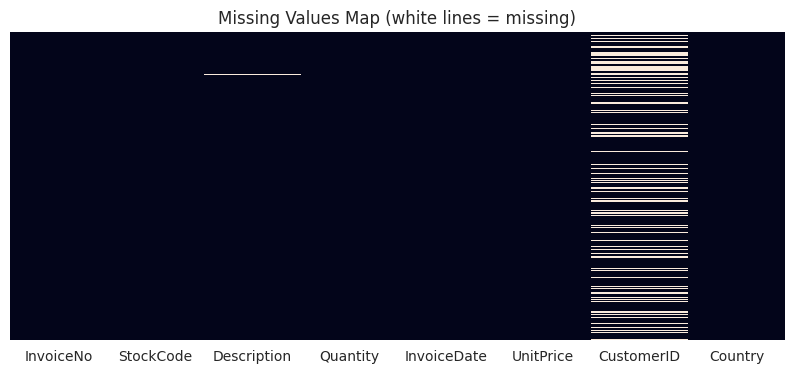

In [10]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Map (white lines = missing)")
plt.show()

### Observations: missing value map
- `CustomerID` shows missing values spread across the entire dataset, with no single block of missing rows. This indicates that the missing values are not caused by one isolated period of data loss.
- `Description` also has missing rows spread through the dataset. The heatmap compresses over 540,000 rows into a small image, so these rows appear as a very thin line.
- The remaining six columns show no missing values.
- The heatmap shows where values are missing but not why. The next steps investigate the cause by checking what these rows have in common.

### Investigation: missing `Description`

**What:** Isolate the rows where `Description` is missing and check their `UnitPrice` and `CustomerID` values.

**Why:** Before deleting or filling anything, we need to know what these rows represent. If they are real sales, deleting them loses information. If they are not sales, keeping them only adds noise.


In [11]:
desc_null = df[df["Description"].isnull()]

print("Rows with missing Description:", len(desc_null))
print("UnitPrice range in these rows:", desc_null["UnitPrice"].min(), "to", desc_null["UnitPrice"].max())
print("All of them also missing CustomerID:", desc_null["CustomerID"].isnull().all())

Rows with missing Description: 1454
UnitPrice range in these rows: 0.0 to 0.0
All of them also missing CustomerID: True


### Observations: missing `Description` rows
- All 1,454 rows with a missing `Description` have a `UnitPrice` of exactly 0, and none of them has a `CustomerID`.
- A transaction with no product name, no price and no customer is not a real sale. These rows look like stock adjustments or system entries.
- Keeping them adds no value to sales analysis or prediction, and they cannot be filled meaningfully because the product name is unknown. They are therefore dropped in the decision step below.

### Investigation: missing `CustomerID`

**What:** Compare rows with a missing `CustomerID` against rows with a known `CustomerID`, in terms of row count and total revenue.

**Why:** About a quarter of the rows have no `CustomerID`. If these rows are real sales, deleting them would remove a meaningful part of the revenue and distort the later analysis. If they carry little value, deleting them is safe. Revenue is the right measure here because it shows how much business these rows represent, not just how many rows there are.

In [12]:
df["is_missing_customer"] = df["CustomerID"].isnull()
df["total_price"] = df["Quantity"] * df["UnitPrice"]

df.groupby("is_missing_customer").agg(
    rows=("InvoiceNo", "size"),
    revenue=("total_price", "sum")
)

,rows,revenue
is_missing_customer,,
False,406829,"8,300,065.81"
True,135080,"1,447,682.12"


### Observations: missing `CustomerID` vs known `CustomerID`
- Rows with a known `CustomerID`: 406,829 rows with a total revenue of 8,300,065.81. Rows with a missing `CustomerID`: 135,080 rows with a total revenue of 1,447,682.12.
- Rows with a missing `CustomerID` are about 25% of all rows (24.93%) but about 15% of the total revenue (1,447,682.12 out of 9,747,747.93, or 14.85%).
- The average revenue per row is about 10.72 for rows with a missing `CustomerID`, compared with about 20.40 for rows with a known `CustomerID`. Rows without a customer therefore tend to carry smaller values, but their total is still substantial.
- These revenue figures are net values, because negative quantities (returns) reduce the totals. Returns and invalid prices are treated in later steps.
- Deleting these rows would remove about 15% of the revenue and could bias the Exploratory Data Analysis and the sales prediction model. `CustomerID` is an identifier and cannot be filled with a mean or mode without inventing customers. The treatment is decided in the next step.

### Decision: treatment of missing values

**What:** Apply the treatment chosen for each column based on the evidence above.

**Why:** The two columns need different treatments.
- **`Description` (1,454 missing, 0.27%):** All of these rows have `UnitPrice = 0` and no `CustomerID`, so they are not sales transactions. They are dropped.
- **`CustomerID` (135,080 missing, about 25% of rows and 15% of net revenue):** An identifier cannot be imputed with a mean or mode, because that would invent customers that do not exist. The rows represent mostly genuine sales, so deleting them would discard a meaningful part of the revenue. They are kept and labelled `"Unknown"`. The flag column `is_missing_customer` keeps them identifiable, so customer-level analysis can exclude them later if needed.

`CustomerID` is also converted from a float to text, because it is an identifier and not a quantity.

In [13]:
df = df.dropna(subset=["Description"])

df["CustomerID"] = df["CustomerID"].astype("Int64").astype("string").fillna("Unknown")

print("Shape after handling missing values:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Rows with unknown customer:", (df["CustomerID"] == "Unknown").sum())

Shape after handling missing values: (540455, 10)
Remaining missing values: 0
Rows with unknown customer: 133626


### Result of the missing value treatment
- The 1,454 rows with a missing `Description` were removed, so the dataset now has 540,455 rows.
- The dataset has 10 columns: the 8 original columns plus the two helper columns `is_missing_customer` and `total_price` created during the investigation.
- No missing values remain in the dataset (0 in total).
- 133,626 rows are labelled `"Unknown"` in `CustomerID`. This is 135,080 minus the 1,454 rows removed earlier, because the removed rows had no `CustomerID` either. These rows stay identifiable through the `is_missing_customer` flag.
- `CustomerID` is now stored as text, so it will not be treated as a number in calculations.

## Step 7A: Removing Exact Duplicate Rows

**What:** Identify and remove rows that are identical across all columns.

**Why:** Duplicate rows count the same transaction twice, which inflates
quantity, revenue and row counts and biases later analysis and the sales
prediction model. Exact duplicates (same invoice, product, quantity, time,
price and customer) are treated as data-entry/system errors, not as
genuine repeat purchases. This is an assumption; a customer buying the
same item twice in the same second with identical details is very unlikely.

In [14]:
# Count exact duplicate rows (all columns identical) before removal
dup_count = df.duplicated().sum()
rows_before = len(df)
print("Exact duplicate rows found:", dup_count)

# Keep the first occurrence and drop the rest
df = df.drop_duplicates(keep="first").reset_index(drop=True)

# Verify the result
rows_after = len(df)
print("Rows before:", rows_before)
print("Rows after :", rows_after)
print("Rows removed:", rows_before - rows_after)
print("Duplicates remaining:", df.duplicated().sum())

Exact duplicate rows found: 5268
Rows before: 540455
Rows after : 535187
Rows removed: 5268
Duplicates remaining: 0


**Observation:**
- 5,268 exact duplicate rows were found and removed (about 0.97% of the 540,455 rows).
- The dataset now has 535,187 rows, and a re-check confirms 0 duplicate rows remain.
- These rows were identical across all columns, so they are treated as data-entry/system errors. This is an assumption, not something that can be proven from the data alone.

In [15]:
# Negative quantity rows that are NOT cancelled invoices
neg_not_cancel = df[(df["Quantity"] < 0) & (~df["InvoiceNo"].astype(str).str.startswith("C"))]
print("Negative qty, not cancelled:", len(neg_not_cancel))
print(neg_not_cancel[["InvoiceNo", "Description", "Quantity", "UnitPrice"]].head(10))
print("Their UnitPrice values:\n", neg_not_cancel["UnitPrice"].describe())

# Rows with UnitPrice <= 0, split by sign
print("UnitPrice == 0:", (df["UnitPrice"] == 0).sum())
print("UnitPrice < 0 :", (df["UnitPrice"] < 0).sum())
print(df[df["UnitPrice"] < 0][["InvoiceNo", "Description", "Quantity", "UnitPrice"]])

Negative qty, not cancelled: 474
      InvoiceNo                 Description  Quantity  UnitPrice
7169     537032                           ?       -30       0.00
12917    537425                       check       -20       0.00
12918    537426                       check       -35       0.00
12962    537432                     damages       -43       0.00
20935    538072                      faulty       -13       0.00
21114    538090                           ?      -723       0.00
21870    538161                Dotcom sales      -100       0.00
21871    538162                Dotcom sales      -100       0.00
41929    540010  reverse 21/5/10 adjustment      -100       0.00
41930    540012  reverse 21/5/10 adjustment      -100       0.00
Their UnitPrice values:
 count   474.00
mean      0.00
std       0.00
min       0.00
25%       0.00
50%       0.00
75%       0.00
max       0.00
Name: UnitPrice, dtype: float64
UnitPrice == 0: 1056
UnitPrice < 0 : 2
       InvoiceNo      Description  Q

In [16]:
zero_price_pos = df[(df["UnitPrice"] == 0) & (df["Quantity"] > 0)]
print("Zero price, positive qty:", len(zero_price_pos))
print(zero_price_pos[["InvoiceNo", "Description", "Quantity", "CustomerID"]].head(10))
print(zero_price_pos["CustomerID"].eq("Unknown").mean())

Zero price, positive qty: 582
      InvoiceNo                       Description  Quantity CustomerID
6282     536941                            amazon        20    Unknown
6283     536942                            amazon        15    Unknown
9090     537197      ROUND CAKE TIN VINTAGE GREEN         1      12647
14020    537534      CREAM SWEETHEART LETTER RACK         1    Unknown
14021    537534  ZINC WILLIE WINKIE  CANDLE STICK         1    Unknown
14022    537534       BOX OF 24 COCKTAIL PARASOLS         2    Unknown
14023    537534             DOORMAT ENGLISH ROSE          3    Unknown
14024    537534             DOORMAT 3 SMILEY CATS         1    Unknown
14025    537534   GREEN REGENCY TEACUP AND SAUCER         1    Unknown
14026    537534     FRENCH BLUE METAL DOOR SIGN 7         1    Unknown
0.9312714776632303


In [17]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancelled invoices:", cancelled.sum())
print("Cancelled and Quantity < 0:", (cancelled & (df["Quantity"] < 0)).sum())
print("Cancelled and Quantity >= 0:", (cancelled & (df["Quantity"] >= 0)).sum())
print("Cancelled total_price sum:", df.loc[cancelled, "total_price"].sum())

Cancelled invoices: 9251
Cancelled and Quantity < 0: 9251
Cancelled and Quantity >= 0: 0
Cancelled total_price sum: -893979.73


## Step 7B: Handling Returns and Invalid Transactions

**What:** Flag cancelled invoices as returns, and remove rows that are not genuine customer sales: negative-quantity rows that are not cancelled invoices, rows with a zero unit price, and rows with a negative unit price.

**Why:**
- Cancelled invoices (InvoiceNo starting with "C") are genuine returns. They are kept and flagged with `is_cancelled` so that gross sales, returns and net revenue can be analysed separately in the EDA, and excluded from the sales prediction target.
- Negative-quantity rows that are not cancelled invoices all have a unit price of 0 and descriptions such as "check", "damages" and "faulty". They appear to be stock adjustments rather than customer purchases, so they are removed.
- Rows with a unit price of 0 and positive quantity have a total price of 0, carry no revenue information, and their cause is not verified. They are removed.
- Two "Adjust bad debt" rows have a negative unit price of -11,062.06. These are accounting adjustments, not product sales, and are removed.

In [18]:
# Flag cancelled invoices (returns) instead of deleting them
df["is_cancelled"] = df["InvoiceNo"].astype(str).str.startswith("C")

# Rows that are not genuine customer sales
non_sale_mask = (
    ((df["Quantity"] < 0) & (~df["is_cancelled"]))  # negative qty, not a cancelled invoice
    | (df["UnitPrice"] <= 0)                        # zero or negative price
)

rows_before = len(df)
print("Rows to remove:", non_sale_mask.sum())

# Keep a copy of the removed rows for the cleaning report, then drop them
removed_rows = df[non_sale_mask].copy()
df = df[~non_sale_mask].reset_index(drop=True)

# Verify
print("Rows before:", rows_before)
print("Rows after :", len(df))
print("Cancelled rows kept (flagged):", df["is_cancelled"].sum())
print("Remaining UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("Remaining negative qty, not cancelled:",
      ((df["Quantity"] < 0) & (~df["is_cancelled"])).sum())

Rows to remove: 1058
Rows before: 535187
Rows after : 534129
Cancelled rows kept (flagged): 9251
Remaining UnitPrice <= 0: 0
Remaining negative qty, not cancelled: 0


**Observation:**
- 1,058 rows were removed: 474 negative-quantity rows that were not cancelled invoices, 582 zero-price rows with positive quantity, and 2 negative-price "Adjust bad debt" rows.
- The dataset now has 534,129 rows. Checks confirm 0 rows with UnitPrice <= 0 and 0 non-cancelled rows with negative Quantity remain.
- 9,251 cancelled invoices (returns) were kept and flagged with `is_cancelled`, so they can be analysed separately in the EDA and excluded from the prediction target.
- The reason behind the zero-price positive-quantity rows is not verified from the data; they were removed because they carry no revenue information.

## Step 8: Standardising Column Names and Fixing Data Types

**What:** Rename all columns to snake_case and convert `invoice_date` from text to a proper datetime type.

**Why:**
- Consistent snake_case names (for example `unit_price` instead of `UnitPrice`) are easier to type, avoid case-related mistakes, and follow common Python conventions.
- `invoice_date` is currently stored as text, so date operations (extracting month, weekday or hour, sorting by time, time-based features for the prediction model) are not possible. A datetime type enables them.

In [19]:
# Rename columns to snake_case using an explicit mapping
df = df.rename(columns={
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "UnitPrice": "unit_price",
    "CustomerID": "customer_id",
    "Country": "country",
})

# Look at the raw date values before converting
print(df["invoice_date"].head())

# Convert text to datetime
df["invoice_date"] = pd.to_datetime(df["invoice_date"])

# Verify
print(df.columns.tolist())
print(df["invoice_date"].dtype)
print("Earliest:", df["invoice_date"].min())
print("Latest  :", df["invoice_date"].max())
print("Missing dates:", df["invoice_date"].isna().sum())

0    12/1/2010 8:26
1    12/1/2010 8:26
2    12/1/2010 8:26
3    12/1/2010 8:26
4    12/1/2010 8:26
Name: invoice_date, dtype: object
['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_missing_customer', 'total_price', 'is_cancelled']
datetime64[ns]
Earliest: 2010-12-01 08:26:00
Latest  : 2011-12-09 12:50:00
Missing dates: 0


**Observation:**
- All column names are now in snake_case.
- `invoice_date` was converted from text (object) to datetime64[ns] with 0 missing values.
- The raw dates are in month/day/year format (for example "12/1/2010 8:26"). Parsing as month-first gives a range of 2010-12-01 to 2011-12-09, about one year, which is consistent with the expected span of the dataset.

## Step 9A: Detecting Outliers with the IQR Method

**What:** Measure outliers in `quantity`, `unit_price` and `total_price` using the IQR rule, on genuine sales only (cancelled returns excluded), and inspect the most extreme rows.

**Why:** Extreme values can distort averages, charts and regression models. Before removing anything, we must check whether they are errors or genuine (for example wholesale bulk orders). Cancelled rows are excluded here because their negative values would be mixed with real sales and misread as outliers.

In [20]:
# Use genuine sales only (exclude cancelled returns)
sales = df[~df["is_cancelled"]]

def iqr_summary(series):
    # IQR rule: values beyond 1.5 * IQR from Q1/Q3 are flagged
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()
    return pd.Series({"q1": q1, "q3": q3, "lower": lower, "upper": upper,
                      "n_outliers": n_out, "pct_outliers": n_out / len(series) * 100})

num_cols = ["quantity", "unit_price", "total_price"]
iqr_table = pd.DataFrame({c: iqr_summary(sales[c]) for c in num_cols}).T
print(iqr_table)

# Inspect the most extreme rows by total_price
print(sales.nlargest(10, "total_price")[
    ["invoice_no", "description", "quantity", "unit_price", "total_price", "customer_id"]])

              q1    q3  lower  upper  n_outliers  pct_outliers
quantity    1.00 11.00 -14.00  26.00   27,111.00          5.17
unit_price  1.25  4.13  -3.07   8.45   37,827.00          7.21
total_price 3.90 17.70 -16.80  38.40   42,624.00          8.12
       invoice_no                          description  quantity  unit_price  \
532648     581483          PAPER CRAFT , LITTLE BIRDIE     80995        2.08   
60678      541431       MEDIUM CERAMIC TOP STORAGE JAR     74215        1.04   
219468     556444       PICNIC BASKET WICKER 60 PIECES        60      649.50   
14634      537632                           AMAZON FEE         1   13,541.33   
295942    A563185                      Adjust bad debt         1   11,062.06   
170792     551697                              POSTAGE         1    8,142.75   
343740     567423  SET OF TEA COFFEE SUGAR TINS PANTRY      1412        5.06   
51851      540815   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114        2.10   
158142     550461   FAIRY CA

**Observation:**
- On genuine sales only (cancelled returns excluded), the IQR rule flags 27,111 rows in `quantity` (5.17%), 37,827 in `unit_price` (7.21%) and 42,624 in `total_price` (8.12%).
- All three distributions are strongly right-skewed. Lower fences are negative, so every flagged value is on the high side.
- The largest `total_price` rows include non-product entries (AMAZON FEE, POSTAGE, Adjust bad debt) and two rows with extreme quantities (80,995 and 74,215 units). Because IQR flags about 8% of rows, flagged values cannot all be treated as errors; each group needs inspection before removal.

## Step 9B: Investigating Extreme and Non-Product Rows

**What:** (1) Check whether the two largest-quantity sales have a matching cancelled (negative) row. (2) List all rows whose stock code does not look like a normal product code.

**Why:** IQR only flags unusual values; it cannot tell errors from genuine bulk orders. An order that was placed and then fully cancelled should not be treated as real demand. Non-product rows (fees, postage, accounting adjustments) are not sales of goods and distort revenue and model training. We verify before deciding what to remove.

In [21]:
# 1) Do the two largest-quantity sales have a matching cancelled row?
big_qty = sales.nlargest(2, "quantity")["quantity"].tolist()
print("Largest quantities:", big_qty)
print(df[df["quantity"].isin([-q for q in big_qty])][
    ["invoice_no", "description", "quantity", "unit_price", "invoice_date", "customer_id"]])

# 2) Non-product rows: stock codes that do not start with 5 digits
non_product = sales[~sales["stock_code"].astype(str).str.match(r"^\d{5}")]
print(non_product.groupby(["stock_code", "description"]).agg(
    rows=("invoice_no", "count"),
    total_price_sum=("total_price", "sum")
).sort_values("rows", ascending=False).head(25))

Largest quantities: [80995, 74215]
       invoice_no                     description  quantity  unit_price  \
60683     C541433  MEDIUM CERAMIC TOP STORAGE JAR    -74215        1.04   
532649    C581484     PAPER CRAFT , LITTLE BIRDIE    -80995        2.08   

              invoice_date customer_id  
60683  2011-01-18 10:17:00       12346  
532649 2011-12-09 09:27:00       16446  
                                                 rows  total_price_sum
stock_code   description                                              
POST         POSTAGE                             1126        78,101.88
DOT          DOTCOM POSTAGE                       706       206,248.77
M            Manual                               316        77,750.27
C2           CARRIAGE                             141         7,051.00
DCGSSGIRL    GIRLS PARTY BAG                       13           144.43
BANK CHARGES Bank Charges                          12           165.00
DCGSSBOY     BOYS PARTY BAG                     

**Observation:**
- The two largest sales (invoice 581483 with 80,995 units and invoice 541431 with 74,215 units) each have a cancelled invoice (C581484 and C541433) with the exact opposite quantity, the same description, the same unit price and the same customer. These orders were placed and then cancelled, so they do not represent real demand.
- Stock codes that do not start with five digits include non-product entries: postage (POST, DOT), carriage (C2), manual entries (M), bank charges, AMAZONFEE, SAMPLES, "Adjust bad debt" (B) and gift vouchers.
- Some non-standard codes (for example DCGS...) are real merchandise such as party bags and dog collars, so the code pattern alone cannot identify non-product rows; each code was checked against its description.

## Step 9C: Removing Cancelled-Out Orders and Non-Product Rows

**What:** Remove (1) the two largest orders together with their matching cancellation rows, and (2) rows whose stock codes represent postage, fees, manual entries, samples, accounting adjustments or gift vouchers.

**Why:**
- An order that was placed and then fully cancelled does not represent real demand. Keeping the sale would add extreme fake values to `total_price`, and keeping only the cancellation would leave an unmatched return.
- Postage, fees, manual entries and bad-debt adjustments are not sales of goods. Gift vouchers are treated as prepaid value, not merchandise demand (an assumption). Keeping these rows would distort revenue analysis and the sales prediction model.
- Stock codes were chosen by checking each code against its description; codes that merely look unusual but describe real products (DCGS...) are kept.
- The removed rows are stored separately for the cleaning report.

In [22]:
# Part 1: the two largest orders and their matching cancellations
pair_qty = [80995, 74215]
pair_mask = df["quantity"].abs().isin(pair_qty)
pair_rows = df[pair_mask]
print(pair_rows[["invoice_no", "description", "quantity", "unit_price",
                 "invoice_date", "customer_id"]].sort_values("invoice_date"))
assert len(pair_rows) == 4, "Unexpected number of matching rows, check before dropping"

# Part 2: non-product stock codes (checked against descriptions)
non_product_codes = ["POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE", "B", "S"]
code_upper = df["stock_code"].astype(str).str.upper()
non_product_mask = code_upper.isin(non_product_codes) | code_upper.str.startswith("GIFT_")

# Remove everything, keeping a copy of the removed rows for the report
rows_before = len(df)
remove_mask = pair_mask | non_product_mask
removed_rows_9 = df[remove_mask].copy()
df = df[~remove_mask].reset_index(drop=True)

# Verify
print("Rows before:", rows_before)
print("Rows after :", len(df))
print("Removed: pair rows =", pair_mask.sum(), "| non-product rows =", non_product_mask.sum())
print("Cancelled rows remaining:", df["is_cancelled"].sum())

# Inspection only: cancelled rows with non-standard stock codes, and PADS rows
leftover = df[df["is_cancelled"] & ~df["stock_code"].astype(str).str.match(r"^\d{5}")]
print(leftover.groupby(["stock_code", "description"]).agg(
    rows=("invoice_no", "count"), total_price_sum=("total_price", "sum")
).sort_values("rows", ascending=False).head(15))
print(df[df["stock_code"].astype(str).str.upper() == "PADS"][
    ["invoice_no", "description", "quantity", "unit_price", "total_price"]])

       invoice_no                     description  quantity  unit_price  \
60678      541431  MEDIUM CERAMIC TOP STORAGE JAR     74215        1.04   
60683     C541433  MEDIUM CERAMIC TOP STORAGE JAR    -74215        1.04   
532648     581483     PAPER CRAFT , LITTLE BIRDIE     80995        2.08   
532649    C581484     PAPER CRAFT , LITTLE BIRDIE    -80995        2.08   

              invoice_date customer_id  
60678  2011-01-18 10:01:00       12346  
60683  2011-01-18 10:17:00       12346  
532648 2011-12-09 09:15:00       16446  
532649 2011-12-09 09:27:00       16446  
Rows before: 534129
Rows after : 531297
Removed: pair rows = 4 | non-product rows = 2828
Cancelled rows remaining: 8759
                            rows  total_price_sum
stock_code description                           
D          Discount           77        -5,696.22
CRUK       CRUK Commission    16        -7,933.43
       invoice_no                 description  quantity  unit_price  \
153949     550193  PADS TO M

**Observation:**
- The two largest orders (invoices 541431 and 581483) were each cancelled on the same day by invoices C541433 and C581484 (16 and 12 minutes later, same customer, exact opposite quantity). All four rows were removed.
- 2,828 non-product rows (postage, carriage, manual entries, bank charges, Amazon fee, samples, bad-debt adjustment and gift vouchers) were removed. This includes 490 cancelled rows with these codes, inferred from the drop in cancelled rows from 9,251 to 8,759 (492 rows, of which 2 are the cancelled large orders).
- The dataset now has 531,297 rows (534,129 before this step).
- Two further non-product code groups remain among cancelled rows: Discount (D, 77 rows) and CRUK Commission (16 rows).

## Step 9C-2: Removing Discount and Commission Entries

**What:** Remove the remaining cancelled non-product rows with stock codes D (Discount) and CRUK (CRUK Commission), and check the exact unit price of the PADS rows.

**Why:** Discounts and commissions are accounting adjustments, not returned goods. Keeping them would mix non-product amounts into the returns analysis, consistent with the earlier removal of other non-product rows. The PADS rows show a unit price of 0.00 after display rounding, so the exact value is inspected before deciding.

In [23]:
# Inspect exact PADS unit prices (display format hides small decimals)
pads = df[df["stock_code"].astype(str).str.upper() == "PADS"]
print(pads["unit_price"].tolist())

# Remove cancelled non-product rows: Discount (D) and CRUK Commission
adj_codes = ["D", "CRUK"]
adj_mask = df["stock_code"].astype(str).str.upper().isin(adj_codes)
print("Rows to remove:", adj_mask.sum(), "| total_price sum:", df.loc[adj_mask, "total_price"].sum())

removed_rows_9b = df[adj_mask].copy()
rows_before = len(df)
df = df[~adj_mask].reset_index(drop=True)

# Verify
print("Rows before:", rows_before, "| after:", len(df))
print("Cancelled rows remaining:", df["is_cancelled"].sum())

[0.001, 0.001, 0.001]
Rows to remove: 93 | total_price sum: -13629.650000000001
Rows before: 531297 | after: 531204
Cancelled rows remaining: 8666


**Observation:**
- 93 cancelled non-product rows were removed: 77 Discount (D) rows and 16 CRUK Commission rows, with a combined total_price of -13,629.65. They are accounting entries, not returned goods.
- The dataset now has 531,204 rows, of which 8,666 are cancelled invoices (genuine returns).
- The three PADS rows have a unit price of 0.001 (effectively zero), so they carry no revenue information.

## Step 9C-3: Removing Near-Zero-Price Rows

**What:** Remove rows whose unit price is below 0.01 (effectively zero).

**Why:** Earlier we removed rows with a unit price of 0 because they carry no revenue information. The three PADS rows have a unit price of 0.001, which behaves the same way, so the same rule is applied for consistency. Using a threshold of 0.01 also guarantees no near-zero prices remain.

In [24]:
# Remove near-zero-price rows (same logic as the earlier zero-price rule)
tiny_mask = df["unit_price"] < 0.01
print("Rows to remove:", tiny_mask.sum())

removed_rows_9c = df[tiny_mask].copy()
rows_before = len(df)
df = df[~tiny_mask].reset_index(drop=True)

# Verify
print("Rows before:", rows_before, "| after:", len(df))
print("Minimum unit_price now:", df["unit_price"].min())

Rows to remove: 3
Rows before: 531204 | after: 531201
Minimum unit_price now: 0.03


**Observation:**
- 3 rows with a unit price of 0.001 (PADS TO MATCH ALL CUSHIONS) were removed using a threshold of 0.01.
- The dataset now has 531,201 rows, and the minimum unit price is 0.03, so no zero or near-zero prices remain.

## Step 9D: Flagging Outliers Instead of Removing Them

**What:** Recompute the IQR fences on the cleaned genuine sales (cancelled returns excluded) and add boolean flag columns for outliers in `quantity`, `unit_price` and `total_price`.

**Why:** The IQR rule flags a large share of rows (about 8% in the earlier check). Large quantities and totals are often genuine wholesale orders, so removing them all would discard real information. Flagging keeps the data intact and lets later steps (EDA, log transform, capping or model comparison with and without outliers) treat them explicitly. The fences are recomputed because the earlier steps removed non-product and cancelled-out rows, which changes the distribution. Cancelled rows are not flagged because their negative values are returns, not unusual sales.

In [25]:
# Genuine sales only (rebuilt from the cleaned df; the old `sales` variable is outdated)
genuine = df[~df["is_cancelled"]]

# Compute IQR fences for each numeric column on genuine sales
fences = {}
for col in ["quantity", "unit_price", "total_price"]:
    q1 = genuine[col].quantile(0.25)
    q3 = genuine[col].quantile(0.75)
    iqr = q3 - q1
    fences[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Add boolean flag columns (cancelled rows are never flagged)
for col, (lower, upper) in fences.items():
    df[f"is_outlier_{col}"] = (~df["is_cancelled"]) & ((df[col] < lower) | (df[col] > upper))

# Combined flag: outlier in at least one column
flag_cols = [f"is_outlier_{c}" for c in fences]
df["is_outlier_any"] = df[flag_cols].any(axis=1)

# Verify
print("Genuine sales rows:", len(genuine))
print({c: (round(l, 2), round(u, 2)) for c, (l, u) in fences.items()})
print(df[flag_cols + ["is_outlier_any"]].sum())
print("Share flagged (any):", round(df["is_outlier_any"].sum() / len(genuine) * 100, 2), "%")
print("Cancelled rows flagged:", df.loc[df["is_cancelled"], "is_outlier_any"].sum())
print("Total rows:", len(df))

Genuine sales rows: 522535
{'quantity': (np.float64(-15.5), np.float64(28.5)), 'unit_price': (np.float64(-3.07), np.float64(8.45)), 'total_price': (np.float64(-16.8), np.float64(38.4))}
is_outlier_quantity       26813
is_outlier_unit_price     35749
is_outlier_total_price    41118
is_outlier_any            79241
dtype: int64
Share flagged (any): 15.16 %
Cancelled rows flagged: 0
Total rows: 531201


**Observation:**
- IQR fences were recomputed on 522,535 genuine sales rows (cancelled returns excluded): quantity (-15.5, 28.5), unit_price (-3.07, 8.45) and total_price (-16.8, 38.4). All lower fences are negative, so only high values are flagged.
- Outlier flags: `is_outlier_quantity` 26,813 rows, `is_outlier_unit_price` 35,749 rows, `is_outlier_total_price` 41,118 rows.
- 79,241 rows (15.16% of genuine sales) are flagged in at least one column (`is_outlier_any`). The combined share is larger than any single flag because different rows are flagged by each column.
- No rows were removed (531,201 rows remain) and no cancelled rows are flagged. Because the IQR rule flags a large share of this right-skewed data, many flagged rows are likely genuine wholesale or low-priced items, so they are flagged rather than deleted.

## Step 9E: Box Plots of Genuine Sales

**What:** We draw box plots of `quantity`, `unit_price` and `total_price` for genuine sales, on a log scale.

**Why:** The task requires visual outlier detection alongside the IQR method. These variables are strongly right-skewed, so on a normal scale the box is squeezed into a thin line near zero. A log scale shows the box, whiskers and outlier points clearly. The plot visually confirms the IQR flags from Step 9D.

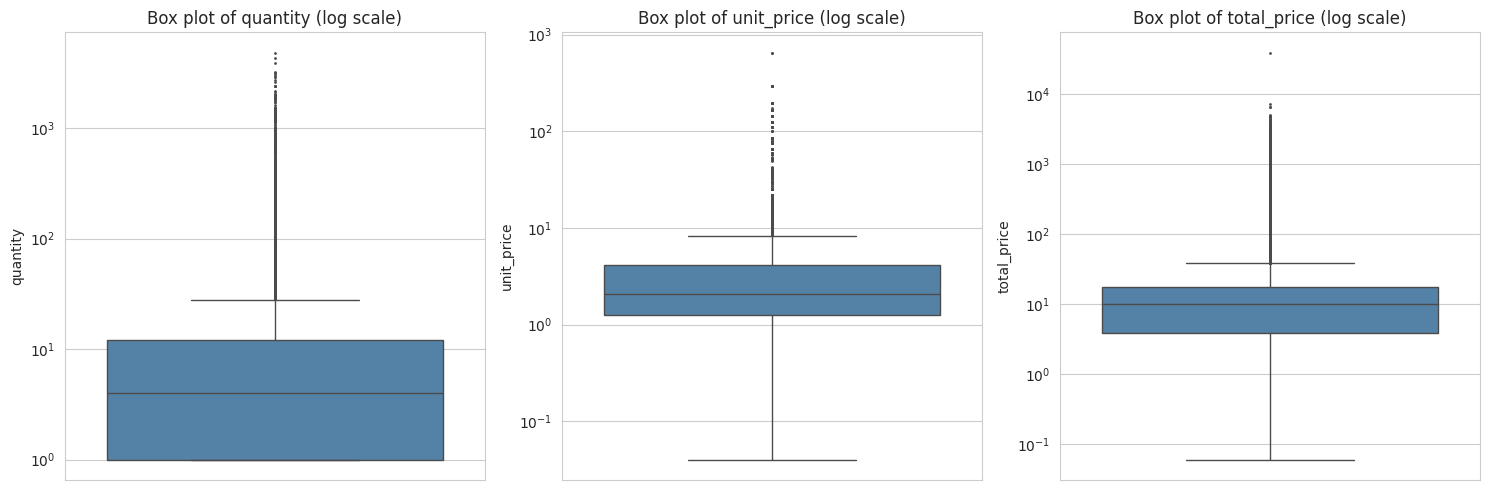

In [26]:
# Genuine sales only (cancelled returns excluded)
genuine = df[~df["is_cancelled"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ["quantity", "unit_price", "total_price"]):
    sns.boxplot(y=genuine[col], ax=ax, color="steelblue", fliersize=1)
    ax.set_yscale("log")  # log scale because the data is right-skewed
    ax.set_title(f"Box plot of {col} (log scale)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

### Observations: Box Plots of Genuine Sales

- All three variables (`quantity`, `unit_price`, `total_price`) are strongly right-skewed. A log scale was needed to see the boxes clearly.
- The upper whiskers match the IQR fences computed in Step 9D (quantity 28.5, unit_price 8.45, total_price 38.4).
- Outlier points appear only above the upper whisker. There are no low outliers, because the lower fences are negative and genuine sales have positive values.
- The outlier points extend far above the whiskers, which confirms that a small number of very large orders and high-priced items stretch the distribution. Since these can be genuine wholesale purchases, they stay in the data and are flagged (`is_outlier_*`) instead of deleted.

## Step 10: Categorical Encoding - Inspection

**What:** Before encoding, we check how many unique values each categorical column has, along with its data type and the most frequent categories.

**Why:** The right encoding method depends on cardinality (number of unique values). A column with 38 categories (e.g. country) can be encoded very differently from a column with 500,000+ unique values (e.g. invoice_no). Encoding blindly can create thousands of useless columns and crash the memory in Colab.

In [27]:
for col in ["invoice_no", "stock_code", "description", "customer_id", "country"]:
    print(col, "->", df[col].nunique(), "unique values | dtype:", df[col].dtype)

print()
print(df["country"].value_counts().head(10))
print()
print(df["customer_id"].value_counts().head(5))

invoice_no -> 23191 unique values | dtype: object
stock_code -> 3920 unique values | dtype: object
description -> 4025 unique values | dtype: object
customer_id -> 4362 unique values | dtype: string
country -> 38 unique values | dtype: object

country
United Kingdom    486196
Germany             9080
France              8218
EIRE                8059
Spain               2462
Netherlands         2326
Belgium             1971
Switzerland         1960
Portugal            1466
Australia           1253
Name: count, dtype: int64

customer_id
Unknown    131549
17841        7800
14911        5806
14096        5095
12748        4440
Name: count, dtype: Int64


### Observations: Categorical Column Inspection

- **invoice_no** has 23,191 unique values across 531,201 rows (about 23 rows per invoice). It is a transaction identifier, not a descriptive feature.
- **stock_code** (3,920 unique) and **description** (4,025 unique) are high-cardinality product identifiers. Description has more unique values than stock_code, which suggests some stock codes carry more than one description text.
- **customer_id** has 4,362 unique values, of which 4,361 are real customers and 1 is the "Unknown" placeholder. The "Unknown" group covers 131,549 rows (about 24.8% of the data), so it must not be treated as a single real customer.
- **country** has only 38 unique values, but United Kingdom alone accounts for 486,196 rows (about 91.5%). The data is heavily dominated by one country.
- Conclusion: only country has low enough cardinality for standard encoding. The other columns need a different treatment or should be excluded from model inputs.

## Step 10B: One-Hot Encoding of Country

**What:** We convert the `country` column (38 categories) into 38 binary columns (`country_<name>`) using one-hot encoding. The result is stored in a separate dataframe, `df_encoded`.

**Why:** Machine learning models need numeric input. Country has no natural order, so label encoding would introduce a false ranking. One-hot encoding avoids this. The original text column is kept in `df` because it is needed for group-by analysis in the EDA task.

**Columns not encoded:** `invoice_no`, `customer_id`, `stock_code` and `description` are identifiers or high-cardinality fields. Encoding them would create thousands of columns or meaningless numbers, so they are excluded from model inputs.

In [28]:
country_dummies = pd.get_dummies(df["country"], prefix="country", dtype="uint8")
df_encoded = pd.concat([df, country_dummies], axis=1)

print("Dummy columns:", country_dummies.shape)
print("df_encoded:", df_encoded.shape)
print("Each row has exactly one country:", (country_dummies.sum(axis=1) == 1).all())
print()
print(country_dummies.sum().sort_values(ascending=False).head(5))

Dummy columns: (531201, 38)
df_encoded: (531201, 53)
Each row has exactly one country: True

country_United Kingdom    486196
country_Germany             9080
country_France              8218
country_EIRE                8059
country_Spain               2462
dtype: uint64


### Observations: One-Hot Encoding of Country

- The `country` column was converted into 38 binary columns. `df_encoded` now has 531,201 rows and 53 columns (15 original + 38 dummy columns).
- The sanity check confirmed that every row has exactly one country flag, so no row was lost or duplicated during encoding.
- The dummy column totals match the earlier value counts (for example, country_United Kingdom = 486,196 rows), which confirms the encoding is consistent with the original data.
- The data is heavily dominated by the United Kingdom (about 91.5% of rows), so most other country columns are very sparse. This is a limitation to keep in mind for modelling.
- The original text `country` column is kept in `df` for group-by analysis in the EDA task.

## Step 11: Validation of the Cleaned Dataset

**What:** We run a set of automated checks on the cleaned dataframe and print PASS or FAIL for each one. We also list the items that were intentionally kept in the data.

**Why:** Cleaning is only trustworthy if it can be verified. These checks prove that duplicates, nulls, naming, data types, date range and invalid prices/quantities are fixed. Outliers and cancelled rows are deliberately retained and flagged, so they are reported separately as "kept by design" instead of being treated as errors.

In [29]:
import re

genuine = df[~df["is_cancelled"]]
cancelled = df[df["is_cancelled"]]

results = []

def check(name, condition):
    # Store the check name and its PASS/FAIL result
    results.append((name, "PASS" if condition else "FAIL"))

# 1. Duplicates and missing values
check("No duplicate rows", df.duplicated().sum() == 0)
check("No null values", df.isnull().sum().sum() == 0)
check("Unknown customer_id rows match is_missing_customer flag",
      (df["customer_id"] == "Unknown").sum() == df["is_missing_customer"].sum())

# 2. Column names and data types
check("All column names are snake_case",
      all(re.fullmatch(r"[a-z0-9_]+", c) for c in df.columns))
check("invoice_date is datetime",
      pd.api.types.is_datetime64_any_dtype(df["invoice_date"]))
check("quantity, unit_price, total_price are numeric",
      all(pd.api.types.is_numeric_dtype(df[c]) for c in ["quantity", "unit_price", "total_price"]))

# 3. Date range
check("Date range is 2010-12-01 to 2011-12-09",
      df["invoice_date"].min().date() == pd.Timestamp("2010-12-01").date()
      and df["invoice_date"].max().date() == pd.Timestamp("2011-12-09").date())

# 4. Quantity and price validity
check("Genuine sales: quantity > 0", (genuine["quantity"] > 0).all())
check("Genuine sales: total_price > 0", (genuine["total_price"] > 0).all())
check("All rows: unit_price >= 0.03", (df["unit_price"] >= 0.03).all())

# 5. Cancelled rows
check("Cancelled rows all have negative quantity", (cancelled["quantity"] < 0).all())
check("Cancelled rows are never flagged as outliers", cancelled["is_outlier_any"].sum() == 0)

for name, status in results:
    print(f"{status} | {name}")

print()
print("KEPT BY DESIGN (not errors):")
print("Total rows:", len(df))
print("Cancelled rows:", len(cancelled))
print("Genuine sales rows:", len(genuine))
print("Rows flagged as outliers:", df["is_outlier_any"].sum())
print("Unknown customer_id rows:", (df["customer_id"] == "Unknown").sum())

PASS | No duplicate rows
PASS | No null values
PASS | Unknown customer_id rows match is_missing_customer flag
PASS | All column names are snake_case
PASS | invoice_date is datetime
PASS | quantity, unit_price, total_price are numeric
PASS | Date range is 2010-12-01 to 2011-12-09
PASS | Genuine sales: quantity > 0
PASS | Genuine sales: total_price > 0
PASS | All rows: unit_price >= 0.03
PASS | Cancelled rows all have negative quantity
PASS | Cancelled rows are never flagged as outliers

KEPT BY DESIGN (not errors):
Total rows: 531201
Cancelled rows: 8666
Genuine sales rows: 522535
Rows flagged as outliers: 79241
Unknown customer_id rows: 131549


### Observations: Validation Results

- All 12 automated checks passed. The cleaned dataset has no duplicate rows and no null values.
- The number of rows labelled "Unknown" in `customer_id` (131,549) equals the number of rows flagged by `is_missing_customer`, so the missing-customer information is preserved in the flag column.
- All column names follow snake_case, `invoice_date` is a datetime column, and `quantity`, `unit_price` and `total_price` are numeric.
- The invoice date range is 2010-12-01 to 2011-12-09, as expected.
- Genuine sales have `quantity > 0` and `total_price > 0`, and every row has `unit_price >= 0.03`, which confirms that the invalid price and quantity rows were removed.
- All cancelled rows have negative quantity and none of them is flagged as an outlier.
- **Kept by design:** the final dataset has 531,201 rows, made up of 522,535 genuine sales and 8,666 cancelled rows. 79,241 rows are flagged as outliers and 131,549 rows have an unknown customer. These were retained and flagged instead of deleted, because IQR flags many valid bulk orders in right-skewed sales data, and cancellations cannot be matched back to their original invoices.

## Step 11B: Summary Statistics of the Cleaned Data

**What:** We print summary statistics for the numeric columns of genuine sales and of cancelled rows separately.

**Why:** Validation should include summary statistics, not only pass/fail checks. Genuine sales and cancelled returns have opposite signs in `quantity` and `total_price`, so mixing them would hide the real distribution.

In [30]:
genuine = df[~df["is_cancelled"]]
cancelled = df[df["is_cancelled"]]

num_cols = ["quantity", "unit_price", "total_price"]

print("Genuine sales:")
print(genuine[num_cols].describe().round(2))
print()
print("Cancelled rows:")
print(cancelled[num_cols].describe().round(2))

Genuine sales:
        quantity  unit_price  total_price
count 522,535.00  522,535.00   522,535.00
mean       10.35        3.27        19.14
std        37.85        4.39        84.67
min         1.00        0.04         0.06
25%         1.00        1.25         3.90
50%         4.00        2.08         9.90
75%        12.00        4.13        17.70
max     4,800.00      649.50    38,970.00

Cancelled rows:
       quantity  unit_price  total_price
count  8,666.00    8,666.00     8,666.00
mean     -13.25        4.42       -26.57
std      120.61        9.13       145.61
min   -9,360.00        0.03    -6,539.40
25%       -6.00        1.45       -16.60
50%       -2.00        2.55        -8.40
75%       -1.00        4.95        -3.30
max       -1.00      295.00        -0.12


### Observations: Summary Statistics of the Cleaned Data

- **Genuine sales (522,535 rows):** `quantity` ranges from 1 to 4,800 (median 4, mean 10.35), `unit_price` from 0.04 to 649.50 (median 2.08, mean 3.27) and `total_price` from 0.06 to 38,970.00 (median 9.90, mean 19.14).
- In all three columns the mean is well above the median, and the maximum is far above the 75th percentile, which confirms strong right skew. This matches the box plots and the IQR fences from Step 9D.
- All genuine sales have positive quantity, unit price and total price, so no invalid values remain.
- **Cancelled rows (8,666 rows):** every row has negative `quantity` and `total_price` (maximum -1 and -0.12), as expected for returns. Their unit prices are positive (minimum 0.03).
- Genuine sales and cancelled rows are summarised separately because mixing them would hide the real sales distribution.

## Step 12: Export the Cleaned Dataset

**What:** We save the cleaned dataframe as `cleaned_online_retail.csv` and reload it to confirm the file was written correctly.

**Why:** The cleaned data is a required deliverable and is the input for the EDA and Sales Prediction tasks. We export `df` (with the original `country` text) instead of `df_encoded`, because EDA needs the text column for group-by analysis and one-hot encoding can be recreated in one line during modelling. Reloading the file proves that no rows or columns were lost during export.

In [31]:
from google.colab import files

# Save the cleaned dataframe without the pandas index column
df.to_csv("cleaned_online_retail.csv", index=False)

# Reload the file to verify the export
check_df = pd.read_csv(
    "cleaned_online_retail.csv",
    dtype={"customer_id": str},        # keep customer IDs as text
    parse_dates=["invoice_date"],      # restore the datetime column
)

print("Exported df shape:", df.shape)
print("Reloaded shape:", check_df.shape)
print("Same column names and order:", list(check_df.columns) == list(df.columns))
print("invoice_date dtype:", check_df["invoice_date"].dtype)
print("Null values after reload:", check_df.isnull().sum().sum())

# Download the file to your computer
files.download("cleaned_online_retail.csv")

Exported df shape: (531201, 15)
Reloaded shape: (531201, 15)
Same column names and order: True
invoice_date dtype: datetime64[ns]
Null values after reload: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Observations: Export Verification

- The cleaned dataframe was exported as `cleaned_online_retail.csv` (about 66.7 MB) with 531,201 rows and 15 columns.
- After reloading, the shape, column names and column order are identical to the original dataframe, `invoice_date` is restored as datetime, and there are no null values. This confirms the export was lossless.
- The original `country` text column is kept in the exported file; one-hot encoding is recreated during modelling.

## Step 13: Collecting Numbers for the Cleaning Report

**What:** We print the saved before-cleaning snapshot and the number of rows removed in each cleaning step.

**Why:** The cleaning report and the before/after comparison table must use verified numbers from the notebook, not numbers typed from memory. This cell also lets us check that the removed rows add up to the total drop from raw to cleaned data.

In [32]:
print("before_df shape:", before_df.shape)
print("before_metrics:", before_metrics)
print()

removed_steps = [
    ("Step 7B (invalid non-cancelled rows)", removed_rows),
    ("Step 9B/9C (largest cancelled orders + non-product codes)", removed_rows_9),
    ("Step 9C-2 (cancelled non-product rows)", removed_rows_9b),
    ("Step 9C-3 (tiny unit_price rows)", removed_rows_9c),
]

for name, r in removed_steps:
    print(name, "->", len(r), "rows")

print()
print("Final cleaned rows:", len(df))

before_df shape: (8, 1)
before_metrics: {'Total rows': 541909, 'Total columns': 8, 'Missing Description': 1454, 'Missing CustomerID': 135080, 'Duplicate rows': 5268, "Cancelled invoices (InvoiceNo starts with 'C')": 9288, 'Negative Quantity rows': 10624, 'UnitPrice <= 0 rows': 2517}

Step 7B (invalid non-cancelled rows) -> 1058 rows
Step 9B/9C (largest cancelled orders + non-product codes) -> 2832 rows
Step 9C-2 (cancelled non-product rows) -> 93 rows
Step 9C-3 (tiny unit_price rows) -> 3 rows

Final cleaned rows: 531201


### Observations: Cleaning Report Numbers

- The raw dataset had 541,909 rows and 8 columns. The final cleaned dataset has 531,201 rows, so 10,708 rows (about 1.98%) were removed in total.
- Rows removed per step: 1,454 with missing description, 5,268 exact duplicates, 1,058 invalid non-cancelled rows (Step 7B), 2,832 non-product and extreme cancelled-order rows (Steps 9B/9C), 93 cancelled non-product rows (Step 9C-2) and 3 tiny unit-price rows (Step 9C-3).
- These counts add up exactly: 1,454 + 5,268 + 1,058 + 2,832 + 93 + 3 = 10,708 = 541,909 - 531,201.
- The raw data also contained 135,080 missing CustomerID values, 9,288 cancelled invoices, 10,624 negative-quantity rows and 2,517 rows with unit price <= 0.

## Step 14: Before vs After Data Quality Comparison

**What:** We build a table that compares key data quality metrics of the raw data (saved earlier in `before_metrics`) with the same metrics calculated live on the cleaned dataframe.

**Why:** The assignment requires a before/after quality comparison. Calculating the "after" values directly from `df` makes the table verifiable and avoids typing numbers by hand.

In [33]:
# Quality metrics of the cleaned dataframe, calculated live
after_metrics = {
    "Total rows": len(df),
    "Total columns": df.shape[1],
    "Missing description": int(df["description"].isnull().sum()),
    "Missing customer_id (true nulls)": int(df["customer_id"].isnull().sum()),
    "Unknown customer_id (flagged)": int((df["customer_id"] == "Unknown").sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Cancelled invoices": int(df["is_cancelled"].sum()),
    "Negative quantity rows": int((df["quantity"] < 0).sum()),
    "Unit price <= 0 rows": int((df["unit_price"] <= 0).sum()),
}

# Raw values saved earlier in before_metrics
before_values = {
    "Total rows": before_metrics["Total rows"],
    "Total columns": before_metrics["Total columns"],
    "Missing description": before_metrics["Missing Description"],
    "Missing customer_id (true nulls)": before_metrics["Missing CustomerID"],
    "Unknown customer_id (flagged)": 0,  # no flag existed before cleaning
    "Duplicate rows": before_metrics["Duplicate rows"],
    "Cancelled invoices": before_metrics["Cancelled invoices (InvoiceNo starts with 'C')"],
    "Negative quantity rows": before_metrics["Negative Quantity rows"],
    "Unit price <= 0 rows": before_metrics["UnitPrice <= 0 rows"],
}

comparison = pd.DataFrame({
    "Metric": list(after_metrics.keys()),
    "Before (raw)": [before_values[k] for k in after_metrics],
    "After (cleaned)": list(after_metrics.values()),
})
comparison["Change"] = comparison["After (cleaned)"] - comparison["Before (raw)"]

print(comparison.to_string(index=False))

                          Metric  Before (raw)  After (cleaned)  Change
                      Total rows        541909           531201  -10708
                   Total columns             8               15       7
             Missing description          1454                0   -1454
Missing customer_id (true nulls)        135080                0 -135080
   Unknown customer_id (flagged)             0           131549  131549
                  Duplicate rows          5268                0   -5268
              Cancelled invoices          9288             8666    -622
          Negative quantity rows         10624             8666   -1958
            Unit price <= 0 rows          2517                0   -2517


### Observations: Before vs After Comparison

- Rows dropped from 541,909 to 531,201 (10,708 rows, about 1.98%). Columns increased from 8 to 15 because 7 helper columns were added (`is_missing_customer`, `total_price`, `is_cancelled` and four outlier flags).
- Missing descriptions, exact duplicates and rows with unit price <= 0 are now 0.
- Missing `customer_id` values are 0 as true nulls, but 131,549 rows are labelled "Unknown" and flagged in `is_missing_customer`. These values were not imputed; the information is preserved in the flag. The difference from the raw count (135,080) is due to rows removed in other cleaning steps.
- Cancelled invoices fell from 9,288 to 8,666. All remaining negative-quantity rows (8,666) are cancelled invoices, so every negative quantity in the cleaned data is an identified return/cancellation.

# Task 1: Cleaning Report

## Summary
The raw UCI Online Retail dataset (541,909 rows, 8 columns) was cleaned into 531,201 rows and 15 columns. Total rows removed: 10,708 (about 1.98%).

## Steps performed
1. **Extra index column** dropped.
2. **Missing values:** 1,454 rows with missing description were dropped. Missing `customer_id` values were kept, flagged in `is_missing_customer` and filled with "Unknown". `total_price = quantity * unit_price` was created.
3. **Duplicates:** 5,268 exact duplicate rows removed.
4. **Invalid rows:** cancelled invoices (InvoiceNo starting with "C") were kept and flagged in `is_cancelled`. Removed 1,058 rows: 474 non-cancelled negative-quantity rows (price 0, descriptions such as damages/faulty), 582 zero-price positive-quantity rows and 2 negative-price bad-debt rows.
5. **Column names and types:** columns renamed to snake_case; `invoice_date` converted to datetime.
6. **Outlier and non-product treatment:**
   - The two largest orders (74,215 and 80,995 units) were cancelled on the same day, so these rows were removed.
   - 2,828 non-product rows (postage, manual entries, bank charges, fees, gift vouchers) and 93 cancelled discount/commission rows were removed.
   - 3 rows with unit price below 0.01 were removed.
   - IQR outliers were flagged (`is_outlier_*` columns, 15.16% of genuine sales) but not deleted.
7. **Encoding:** `country` (38 values) was one-hot encoded into `df_encoded`. Identifier columns (`invoice_no`, `customer_id`, `stock_code`, `description`) were not encoded because of their high cardinality.
8. **Validation:** 12 automated checks passed. The cleaned file `cleaned_online_retail.csv` was exported and reloaded successfully (531,201 rows, 15 columns).

## Rows removed per step
| Step | Rows removed |
|---|---|
| Missing description | 1,454 |
| Exact duplicates | 5,268 |
| Invalid non-cancelled rows | 1,058 |
| Non-product codes and extreme cancelled orders | 2,832 |
| Cancelled non-product rows | 93 |
| Tiny unit price rows | 3 |
| **Total** | **10,708** |

## Assumptions and limitations
- Exact duplicate rows were treated as data-entry errors.
- Gift vouchers were treated as non-merchandise (a judgement call).
- The reason for 582 zero-price positive-quantity rows was not verified.
- Cancelled rows cannot be matched to their original invoices, so they are flagged rather than netted off.
- Missing customer IDs (131,549 rows) were labelled "Unknown", not imputed, so customer-level analysis excludes them.
- The IQR method flags a large share of right-skewed sales data, so outliers were flagged instead of removed.

**Task 1 complete.** The cleaned dataset was exported as `cleaned_online_retail.csv` and is used as the input for Task 2 (EDA) and Task 3 (Sales Prediction).